# 1. Quick start: simulating single-cell counts with `NegBinCopula`

This notebook introduces the main `scDesigner` workflow: specify a count model, fit it to an `AnnData` object, inspect the fitted parameters, and simulate under either the observed or a new covariate design.

The example came from the [scVelo pancreas dataset](https://scvelo.readthedocs.io/en/stable/scvelo.datasets.pancreas.html) and was originally published by [Bastidas-Ponce et. al.](https://journals.biologists.com/dev/article/146/12/dev173849/19483/Comprehensive-single-cell-mRNA-profiling-reveals-a), who studied pancreatic endocrinogenesis. Our example subset contains 2,087 cells from a single trajectory and 100 highly variable genes.

In [1]:
import numpy as np
import torch

from scdesigner.datasets import pancreas

example_sce = pancreas()
example_sce

AnnData object with n_obs × n_vars = 2087 × 1000
    obs: 'clusters_coarse', 'clusters', 'S_score', 'G2M_score', 'cell_type', 'sizeFactor', 'pseudotime'
    var: 'highly_variable_genes'
    uns: 'X_name', 'clusters_coarse_colors', 'clusters_colors', 'day_colors', 'neighbors', 'pca'
    obsm: 'PCA', 'UMAP', 'X_pca', 'X_umap'
    layers: 'X', 'cpm', 'logcounts', 'spliced', 'unspliced'
    obsp: 'connectivities', 'distances'

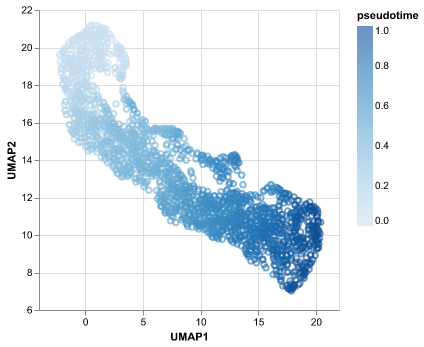

In [2]:
from scdiagnostics import plot_umap

plot_umap(example_sce, color="pseudotime")

From the UMAP, we can see that the cells show a clear lineage development pattern, suggesting that the `pseudotime` metadata may be useful for predicting count matrix across genes and cells at various developmental stages.

## 1. Specify simulator

The simulators take in cell-by-gene `AnnData` objects for model fitting, where the count matrix is stored in `X`, and the metadata is stored in `obs`. For model fitting, we are interested in modeling the count matrix `X` with respect to the covariates in `obs`.

In [4]:
example_sce.X

array([[103.,   0.,  86., ...,   0.,   0.,   0.],
       [  1.,   0.,   2., ...,   0.,   1.,   1.],
       [  0.,   2.,  19., ...,   0.,   0.,   1.],
       ...,
       [ 75.,   0.,  64., ...,   0.,   0.,   1.],
       [  0.,   0.,  59., ...,   0.,   0.,   1.],
       [  0.,   0.,   1., ...,   0.,   1.,   0.]], shape=(2087, 1000))

In [ ]:
example_sce.obs

,clusters_coarse,clusters,S_score,G2M_score,cell_type,sizeFactor,pseudotime
AAACCTGAGAGGGATA,Pre-endocrine,Pre-endocrine,-0.224902,-0.252071,Pre-endocrine,0.813018,0.677236
AAACCTGGTAAGTGGC,Ngn3 high EP,Ngn3 high EP,-0.179981,-0.126030,Ngn3 high EP,0.824834,0.431569
AAACGGGCAAAGAATC,Endocrine,Beta,-0.174345,-0.221602,Beta,1.045403,0.749373
AAACGGGGTACAGTTC,Endocrine,Beta,-0.186562,-0.157197,Beta,1.506890,0.925441
AAACGGGGTGAAATCA,Ngn3 high EP,Ngn3 high EP,-0.055381,1.020705,Ngn3 high EP,1.398903,0.380345
...,...,...,...,...,...,...,...
TTTGGTTTCACTTACT,Ngn3 high EP,Ngn3 high EP,0.079044,-0.300046,Ngn3 high EP,1.765861,0.103478
TTTGGTTTCCTTTCGG,Endocrine,Beta,-0.186055,-0.185440,Beta,0.628062,0.792967
TTTGTCAAGAATGTGT,Pre-endocrine,Pre-endocrine,-0.298142,-0.254821,Pre-endocrine,1.099888,0.699019
TTTGTCAAGTGACATA,Pre-endocrine,Pre-endocrine,-0.235896,-0.266101,Pre-endocrine,1.512962,0.590720


Since our example dataset contains raw, nonnegative integer counts in `X`, a natural approach would be to start with `NegBinCopula`, the default choice of `scDesigner` simulators. Refer to [distributions overview](03-distributions-overview.ipynb) for guidelines on model choices.

`NegBinCopula` allows fitting models on three aspects of the data: `mean_formula`, `dispersion_formula`, and `copula_formula`. The formula inputs transform the raw `obs` covariate matrix into appropriate regression design matrices for the corresponding parameters.

Currently, `mean_formula` and `dispersion_formula` accepts both numerical and categorical variable inputs, but `copula_formula` only accepts categorical grouping variables. 

In [ ]:
from scdesigner.simulators import NegBinCopula

sim = NegBinCopula(
    mean_formula="~ bs(pseudotime, df=10)",
    dispersion_formula="~ bs(pseudotime, df=3)",
    copula_formula="~ 1",
)

The `~ bs(pseudotime)` in the mean and dispersion formulas expands the single numeric `pseudotime` variable into a B-spline basis, allowing non-linear relationship between the response variable and the covariate, and `~1` in the copula formula assumes one shared correlation structure across all cell groups. 

For detailed use of the marginal and copula formula and interpretation of the coefficients, check out [02-simulator-internals](02-simulator-internals.ipynb).

## 2. Fit the marginal and copula models

The `fit()` function in `scDesigner` carries out the actual model fitting process, where it first fits each gene's distributions independently in parallel, then aggregate the results to estimate the gene-gene correlations. Training stops when the model reach `max_epochs` or if the loss fails to improve after `min_epochs`. 

Refer to [simulator internals](02-simulator-internals.ipynb) for more information about the hyperparameters and technical details about the model.

In [ ]:
# Seed both libraries because optimization and copula fitting use random numbers.
np.random.seed(0)
torch.manual_seed(0)

sim.fit(
    example_sce,
    max_epochs=500,
    min_epochs=20
)

Estimating copula correlation: 100%|██████████| 3/3 [00:00<00:00,  9.74it/s]


The fit history records the marginal training and validation losses. It is worth checking that the best epoch was not the first epoch, the losses are finite, and validation loss did not deteriorate strongly while training loss continued to fall.

In [ ]:
print(
    f"best epoch: {sim.marginal.best_epoch}; "
    f"stopped epoch: {sim.marginal.stopped_epoch}"
)
sim.marginal.fit_history_df.tail()

best epoch: 257; stopped epoch: 267


,epoch,train_loss,val_loss,best,stopped
262,263,1.870078,1.876753,False,False
263,264,1.870060,1.876734,False,False
264,265,1.870043,1.876716,False,False
265,266,1.870026,1.876698,False,False
266,267,1.870009,1.876680,False,True


For thousands of genes, full copula estimation can be unecessarily expensive and potentially overfit, especially in the small sample size regime. In this case, pass `top_k=<number>` to `fit()` to model a full correlation block only for the most highly expressed genes; the remaining genes retain fitted negative-binomial marginals but are treated as independent in the copula. 

See the [large-scale simulation example](15-large-scale-simulation.ipynb) for more detail on `scDesigner`'s scalability design.

## 3. Inspect fitted values and parameters

`predict()` returns the fitted marginal parameters for each cell-gene pair in dictionary format. It uses the training covariates by default when no `obs` values are specified; we can also specify new covariate values to predict the means and dispersions. 

The fitted coefficients and copula structures are available through `sim.parameters`, `sim.marginal`, and `sim.copula` (see [distributions overview](03-distributions-overview.ipynb)).

In [ ]:
fitted = sim.predict()
fitted['mean']

array([[4.8407379e+01, 1.8448949e+00, 5.5794674e+01, ..., 4.3633088e-01,
        1.3374237e-03, 1.2136539e+00],
       [1.2564061e+00, 1.5454294e-01, 5.7681947e+00, ..., 1.9728613e+00,
        9.0026306e-03, 3.8604097e+00],
       [1.1042807e+02, 8.7116327e+00, 4.4998951e+01, ..., 4.4377929e-01,
        3.3875615e-03, 6.7330551e-01],
       ...,
       [6.4041885e+01, 2.8666463e+00, 5.3730453e+01, ..., 4.2683348e-01,
        1.5948187e-03, 1.0133742e+00],
       [1.3218869e+01, 4.6081355e-01, 4.7346523e+01, ..., 6.1435080e-01,
        1.5211997e-03, 2.3320646e+00],
       [5.8476835e-01, 1.9426128e-01, 2.5213832e-01, ..., 3.7348113e+00,
        1.3912406e-02, 2.2023039e+00]], dtype=float32)

In [ ]:
# Rows are formula terms and columns are genes.
sim.parameters["marginal"]["mean"].iloc[:, :5]

,Pyy,Iapp,Chgb,Rbp4,Spp1
Intercept,-0.628266,-1.775196,1.017537,-0.459690,3.880537
"bs(pseudotime, df=5)[1]",1.352797,2.312887,-12.853308,0.267358,1.696402
"bs(pseudotime, df=5)[2]",-1.908343,-1.118718,1.017034,-3.123623,-5.136424
"bs(pseudotime, df=5)[3]",5.332261,0.848964,4.120718,4.839564,-6.980855
"bs(pseudotime, df=5)[4]",6.538476,7.932713,1.712499,4.609818,-4.260563
"bs(pseudotime, df=5)[5]",5.089781,7.862651,1.491324,3.887867,-5.182944


`complexity()` reports marginal and copula AIC/BIC. These criteria can help compare candidate formula specifications, but comparisons are meaningful only when models are fitted to the same cells and genes.

In [ ]:
sim.complexity(batch_size=1024)

Computing log-likelihood...: 100%|██████████| 3/3 [00:00<00:00, 18.90it/s]


{'marginal_aic': 782288.5625,
 'marginal_bic': 786239.000534954,
 'copula_aic': -9285.13354155235,
 'copula_bic': 18650.106848479794}

## 4. New count matrix simulation

Similar to `predict()`, calling `sample()` without `obs` generates a count matrix based on training `obs` data, and calling `sample()` with new `obs` values gives a count matrix with the new corresponding mean and dispersion parameters. 

The output is an `AnnData` object where `.X` contains the simulated counts, and `.obs` and `.var` carry the template metadata used to simulate them.

In [ ]:
sampled_sce = sim.sample()
sampled_sce

AnnData object with n_obs × n_vars = 2087 × 100
    obs: 'clusters_coarse', 'clusters', 'S_score', 'G2M_score', 'cell_type', 'sizeFactor', 'pseudotime'
    var: 'highly_variable_genes'

Besides naive simulation, people can also use the simulation tool for downstream analysis. For example, we can easily perform negative control by nullifying certain covariate inputs (see [transformations](05-transformations.ipynb) for more details).

## 5. Simulation validation

A successful fit should reproduce the features targeted by the model, such as gene means, variances, zero fractions, library sizes, and correlations. Here we present the UMAP as a simple visual check.

In [ ]:
from scdiagnostics import compare_umap

compare_umap(example_sce, sampled_sce, color="pseudotime")

/Users/pyl/anaconda3/envs/scdesigner/lib/python3.11/site-packages/anndata/_core/storage.py:39: ImplicitModificationWarning: X should not be a np.matrix, use np.ndarray instead.
  warnings.warn(msg, ImplicitModificationWarning)
/Users/pyl/anaconda3/envs/scdesigner/lib/python3.11/site-packages/scdiagnostics/data.py:39: FutureWarning: Use anndata.concat instead of AnnData.concatenate, AnnData.concatenate is deprecated and will be removed in the future. See the tutorial for concat at: https://anndata.readthedocs.io/en/latest/concatenation.html
  return real_.concatenate(simulated_, join="outer", batch_key=None)


alt.FacetChart(...)